In [1]:
from ultralytics import YOLO

MODEL_PATH = r"C:\Users\nanda\OneDrive\Documents\UAV - Computer Vision\outputs\yolov11_baseline-4\weights\best.pt"

model = YOLO(MODEL_PATH)

print("Model loaded successfully.")
print("\nClass-wise results:")
print(model.names)

Model loaded successfully.

Class-wise results:
{0: 'Pedestrian', 1: 'People', 2: 'Bicycle', 3: 'Car', 4: 'Van', 5: 'Truck', 6: 'Tricycle', 7: 'Awning Tricycle', 8: 'Bus', 9: 'Motor'}


In [4]:
from pathlib import Path

base = Path(r"C:\Users\nanda\OneDrive\Documents\UAV - Computer Vision")

yaml_files = list(base.rglob("*.yaml")) + list(base.rglob("*.yml"))

for f in yaml_files:
    print(f)

C:\Users\nanda\OneDrive\Documents\UAV - Computer Vision\configs\inference.yaml
C:\Users\nanda\OneDrive\Documents\UAV - Computer Vision\configs\model_config.yaml
C:\Users\nanda\OneDrive\Documents\UAV - Computer Vision\configs\train.yaml
C:\Users\nanda\OneDrive\Documents\UAV - Computer Vision\data\data.yaml
C:\Users\nanda\OneDrive\Documents\UAV - Computer Vision\data\raw\VisDrone-2019-DET\VisDrone.yaml
C:\Users\nanda\OneDrive\Documents\UAV - Computer Vision\outputs\yolov11_baseline\args.yaml
C:\Users\nanda\OneDrive\Documents\UAV - Computer Vision\outputs\yolov11_baseline-2\args.yaml
C:\Users\nanda\OneDrive\Documents\UAV - Computer Vision\outputs\yolov11_baseline-3\args.yaml
C:\Users\nanda\OneDrive\Documents\UAV - Computer Vision\outputs\yolov11_baseline-4\args.yaml
C:\Users\nanda\OneDrive\Documents\UAV - Computer Vision\outputs\yolov11_baseline-5\args.yaml


In [6]:
import pandas as pd

error_analysis = pd.DataFrame({
    "Issue": [
        "Small objects",
        "Class imbalance",
        "Crowded scenes",
        "Object occlusion",
        "Low-confidence detections"
    ],
    "Evidence": [
        "60.47% of annotated objects are small",
        "Car has ~144,867 objects vs ~3,246 Awning Tricycles",
        "Dense UAV traffic scenes contain overlapping objects",
        "Pedestrians, bicycles and vehicles are frequently partially hidden",
        "Weak classes often produce confidence values around 0.20–0.40"
    ],
    "Impact": [
        "Missed detections and lower recall",
        "Minority classes have substantially lower AP",
        "Duplicate/missed detections",
        "Lower localization and classification accuracy",
        "Threshold selection affects precision-recall balance"
    ]
})

error_analysis

,Issue,Evidence,Impact
0,Small objects,60.47% of annotated objects are small,Missed detections and lower recall
1,Class imbalance,"Car has ~144,867 objects vs ~3,246 Awning Tric...",Minority classes have substantially lower AP
2,Crowded scenes,Dense UAV traffic scenes contain overlapping o...,Duplicate/missed detections
3,Object occlusion,"Pedestrians, bicycles and vehicles are frequen...",Lower localization and classification accuracy
4,Low-confidence detections,Weak classes often produce confidence values a...,Threshold selection affects precision-recall b...


In [7]:
import pandas as pd

results_path = r"C:\Users\nanda\OneDrive\Documents\UAV - Computer Vision\outputs\yolov11_baseline-4\results.csv"

results = pd.read_csv(results_path)

# Show all available metrics
print("Available columns:")
print(results.columns.tolist())

print("\nLast 5 epochs:")
display(results.tail())

Available columns:
['epoch', 'time', 'train/box_loss', 'train/cls_loss', 'train/dfl_loss', 'metrics/precision(B)', 'metrics/recall(B)', 'metrics/mAP50(B)', 'metrics/mAP50-95(B)', 'val/box_loss', 'val/cls_loss', 'val/dfl_loss', 'lr/pg0', 'lr/pg1', 'lr/pg2']

Last 5 epochs:


,epoch,time,train/box_loss,train/cls_loss,train/dfl_loss,metrics/precision(B),metrics/recall(B),metrics/mAP50(B),metrics/mAP50-95(B),val/box_loss,val/cls_loss,val/dfl_loss,lr/pg0,lr/pg1,lr/pg2
15,16,7083.79,1.79155,1.32685,0.90628,0.29617,0.23223,0.18258,0.09738,1.70008,1.25333,0.90539,0.000184,0.000184,0.000184
16,17,7513.82,1.78130,1.31291,0.90454,0.30419,0.23466,0.18552,0.10049,1.69081,1.23984,0.90500,0.000149,0.000149,0.000149
17,18,7954.98,1.76052,1.29342,0.90209,0.30292,0.23103,0.18637,0.10102,1.68353,1.22903,0.90442,0.000113,0.000113,0.000113
18,19,8398.22,1.75622,1.27884,0.90027,0.31236,0.23527,0.19029,0.10307,1.67268,1.22251,0.90300,0.000078,0.000078,0.000078
19,20,8842.21,1.74578,1.27404,0.89783,0.30892,0.23342,0.19026,0.10320,1.67476,1.22425,0.90276,0.000042,0.000042,0.000042


In [8]:
# Show only validation/performance metric columns
metric_cols = [
    col for col in results.columns
    if "metrics" in col.lower()
]

print("Performance metrics:")
for col in metric_cols:
    print(col)

print("\nFinal epoch metrics:")
print(results[metric_cols].iloc[-1])

Performance metrics:
metrics/precision(B)
metrics/recall(B)
metrics/mAP50(B)
metrics/mAP50-95(B)

Final epoch metrics:
metrics/precision(B)    0.30892
metrics/recall(B)       0.23342
metrics/mAP50(B)        0.19026
metrics/mAP50-95(B)     0.10320
Name: 19, dtype: float64


In [10]:
# Clean column names
results.columns = results.columns.str.strip()

print("ALL COLUMNS IN results.csv:\n")

for i, col in enumerate(results.columns):
    print(i, repr(col))

ALL COLUMNS IN results.csv:

0 'epoch'
1 'time'
2 'train/box_loss'
3 'train/cls_loss'
4 'train/dfl_loss'
5 'metrics/precision(B)'
6 'metrics/recall(B)'
7 'metrics/mAP50(B)'
8 'metrics/mAP50-95(B)'
9 'val/box_loss'
10 'val/cls_loss'
11 'val/dfl_loss'
12 'lr/pg0'
13 'lr/pg1'
14 'lr/pg2'


In [11]:
# Final epoch
final = results.iloc[-1]

print("FINAL EPOCH RESULTS")
print("-------------------")
print(f"Epoch       : {int(final['epoch'])}")
print(f"Precision   : {final['metrics/precision(B)']:.4f}")
print(f"Recall      : {final['metrics/recall(B)']:.4f}")
print(f"mAP@50      : {final['metrics/mAP50(B)']:.4f}")
print(f"mAP@50-95   : {final['metrics/mAP50-95(B)']:.4f}")


# Best epoch based on mAP@50-95
best_idx = results['metrics/mAP50-95(B)'].idxmax()
best = results.loc[best_idx]

print("\nBEST EPOCH")
print("----------")
print(f"Epoch       : {int(best['epoch'])}")
print(f"Precision   : {best['metrics/precision(B)']:.4f}")
print(f"Recall      : {best['metrics/recall(B)']:.4f}")
print(f"mAP@50      : {best['metrics/mAP50(B)']:.4f}")
print(f"mAP@50-95   : {best['metrics/mAP50-95(B)']:.4f}")

FINAL EPOCH RESULTS
-------------------
Epoch       : 20
Precision   : 0.3089
Recall      : 0.2334
mAP@50      : 0.1903
mAP@50-95   : 0.1032

BEST EPOCH
----------
Epoch       : 20
Precision   : 0.3089
Recall      : 0.2334
mAP@50      : 0.1903
mAP@50-95   : 0.1032


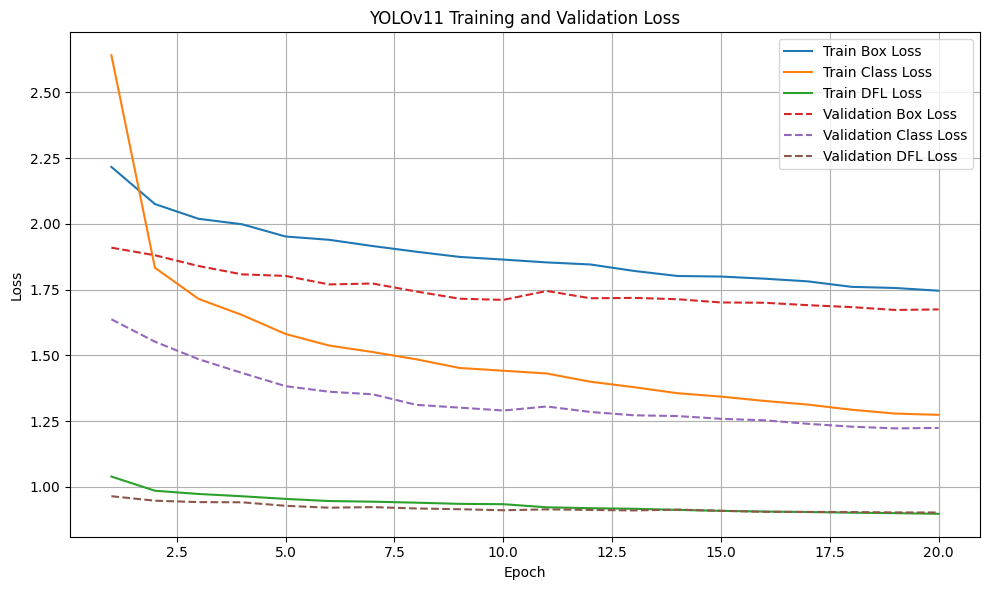

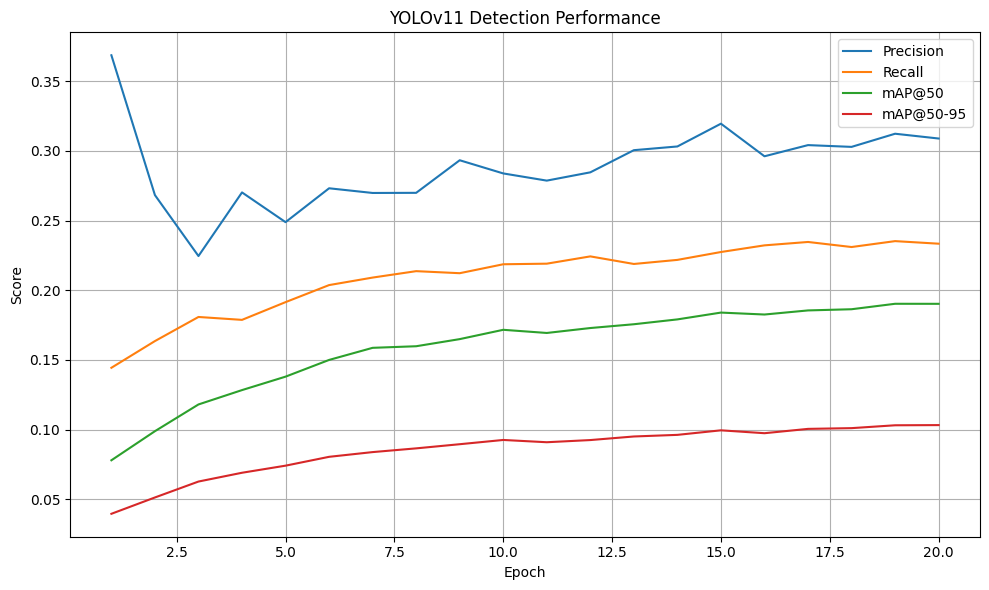

In [12]:
import matplotlib.pyplot as plt

# -----------------------------
# 1. LOSS CURVES
# -----------------------------
plt.figure(figsize=(10, 6))

plt.plot(results['epoch'], results['train/box_loss'], label='Train Box Loss')
plt.plot(results['epoch'], results['train/cls_loss'], label='Train Class Loss')
plt.plot(results['epoch'], results['train/dfl_loss'], label='Train DFL Loss')

plt.plot(results['epoch'], results['val/box_loss'],
         linestyle='--', label='Validation Box Loss')
plt.plot(results['epoch'], results['val/cls_loss'],
         linestyle='--', label='Validation Class Loss')
plt.plot(results['epoch'], results['val/dfl_loss'],
         linestyle='--', label='Validation DFL Loss')

plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.title('YOLOv11 Training and Validation Loss')
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


# -----------------------------
# 2. PERFORMANCE METRICS
# -----------------------------
plt.figure(figsize=(10, 6))

plt.plot(results['epoch'], results['metrics/precision(B)'],
         label='Precision')
plt.plot(results['epoch'], results['metrics/recall(B)'],
         label='Recall')
plt.plot(results['epoch'], results['metrics/mAP50(B)'],
         label='mAP@50')
plt.plot(results['epoch'], results['metrics/mAP50-95(B)'],
         label='mAP@50-95')

plt.xlabel('Epoch')
plt.ylabel('Score')
plt.title('YOLOv11 Detection Performance')
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()